In [1]:
import sys, os
sys.path.insert(0, os.getcwd())

import pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import jax
import jax.numpy as jnp

from train import (load_training_params, setup_training, run_training_loop,
                   evaluate_training, plot_training_log,
                   _make_grad_mask, _make_transfer_train_step)

In [2]:
# ── Transfer source / target ───────────────────────────────────────────────────
source_task = 'wn'
train_task  = 'harmonic'
task_list   = ['pure', 'harmonic', 'wn']

# Which parameters to train during transfer:
#   'all'                  — train everything
#   'context'              — W_in rows for the 3 context channels only
#   'sensory'              — W_in rows for the n_freq frequency channels only
#   ['context', 'sensory'] — both W_in input slices (fixation row stays frozen)
#   ['W_rec', 'b_rec']     — any list of top-level param names
#   ['context', 'W_rec']   — mix of special strings and param names
trainable = ['context', 'sensory']

# Which source checkpoint to start from:
# None = checkpoint.pkl (final); int = checkpoint_{step}.pkl (snapshot)
source_step = None

# ── Training schedule ─────────────────────────────────────────────────────────
n_steps         = 10000
k               = 100
seed            = 0
eval_with_noise = True

# ── Save location ─────────────────────────────────────────────────────────────
RESULTS_DIR = Path(os.environ.get('TONE_RESULTS_DIR', 'results'))
save_dir = str(RESULTS_DIR / f'transfer_{source_task}_to_{train_task}') + '/'

In [3]:
source_dir  = RESULTS_DIR / source_task / f'{source_task}_0_lr5e-06_bs128_noise0.5'
ckpt_fname  = f'checkpoint_{source_step}.pkl' if source_step else 'checkpoint.pkl'
source_ckpt_path = source_dir / ckpt_fname

with open(source_ckpt_path, 'rb') as f:
    source_ckpt = pickle.load(f)
init_params = source_ckpt['params']
src_step    = source_ckpt['step']
print(f'Loaded: {source_ckpt_path}  (step {src_step})')

# Insert trainable as a subfolder: transfer_wn_to_harmonic/context/...
trainable_label = trainable if isinstance(trainable, str) else '+'.join(trainable)
run_save_dir = str(Path(save_dir) / trainable_label) + '/'

state, cfg = setup_training(train_task, task_list, n_steps, k, seed, run_save_dir,
                             init_params=init_params, trainable=trainable)

# Save source weights as the starting-point reference
with open(cfg['save_path'] / 'checkpoint_init.pkl', 'wb') as f:
    pickle.dump({'params': init_params, 'step': src_step,
                 'source_task': source_task,
                 'source_ckpt_path': str(source_ckpt_path)}, f)

n_freq     = cfg['n_freq']
grad_mask  = _make_grad_mask(state.params, trainable, n_freq)
train_step = _make_transfer_train_step(grad_mask)

n_trainable = sum(int(jnp.sum(m > 0)) for m in jax.tree_util.tree_leaves(grad_mask))
n_total     = sum(int(p.size) for p in jax.tree_util.tree_leaves(state.params))
print(f'source -> target : {source_task} (step {src_step}) -> {train_task}')
print(f'trainable        : {trainable}  ({n_trainable}/{n_total} params)')

Loaded: results\wn\wn_0_lr5e-06_bs128_noise0.5\checkpoint.pkl  (step 15000)
task_list : ['pure', 'harmonic', 'wn']
train_task: harmonic
n_freq=50  n_in=54 (freq+fixation+context)  n_rnn=128  alpha=0.100
pulse_dur=50ms  n_pulses=8  stim_dur=400ms  tdim=240 (2400ms)
save_dir  : C:\Users\zhixi\Documents\GitHub\tone_generalize\code\results\transfer_wn_to_harmonic\context+sensory\harmonic_0_lr5e-05_bs128_noise0.5_nrnn128
source -> target : wn (step 15000) -> harmonic
trainable        : ['context', 'sensory']  (6784/23553 params)


In [4]:
state, snapshots = run_training_loop(state, train_task, task_list, cfg,
                               train_step_fn=train_step)

step    100  loss=0.3648
step    200  loss=0.3028
step    300  loss=0.2559
step    400  loss=0.2751
step    500  loss=0.2431
step    600  loss=0.2375
step    700  loss=0.2406
step    800  loss=0.1789
step    900  loss=0.1896
step   1000  loss=0.1704
step   1100  loss=0.1554
step   1200  loss=0.1479
step   1300  loss=0.1163
step   1400  loss=0.1074
step   1500  loss=0.1002
step   1600  loss=0.0801
step   1700  loss=0.0650
step   1800  loss=0.0609
step   1900  loss=0.0541
step   2000  loss=0.0473
step   2100  loss=0.0428
step   2200  loss=0.0423
step   2300  loss=0.0392
step   2400  loss=0.0356
step   2500  loss=0.0345
step   2600  loss=0.0323
step   2700  loss=0.0302
step   2800  loss=0.0286
step   2900  loss=0.0290
step   3000  loss=0.0270
step   3100  loss=0.0248
step   3200  loss=0.0269
step   3300  loss=0.0250
step   3400  loss=0.0247
step   3500  loss=0.0231
step   3600  loss=0.0237
step   3700  loss=0.0233
step   3800  loss=0.0236
step   3900  loss=0.0214
step   4000  loss=0.0225


In [5]:
# ── Evaluate each training snapshot on source + target task ───────────────────
log = evaluate_training(state, snapshots,
                        tasks=[source_task, train_task],
                        cfg=cfg,
                        eval_with_noise=eval_with_noise)

step    100  wn: hit=0.91 FA=0.00  |  harmonic: hit=0.94 FA=0.97
step    200  wn: hit=0.89 FA=0.00  |  harmonic: hit=0.99 FA=0.97
step    300  wn: hit=0.94 FA=0.00  |  harmonic: hit=0.99 FA=1.00
step    400  wn: hit=0.94 FA=0.00  |  harmonic: hit=1.00 FA=0.99
step    500  wn: hit=0.98 FA=0.00  |  harmonic: hit=1.00 FA=0.99
step    600  wn: hit=0.91 FA=0.00  |  harmonic: hit=0.99 FA=1.00
step    700  wn: hit=0.97 FA=0.00  |  harmonic: hit=1.00 FA=0.99
step    800  wn: hit=0.97 FA=0.00  |  harmonic: hit=1.00 FA=0.99
step    900  wn: hit=0.95 FA=0.00  |  harmonic: hit=1.00 FA=0.99
step   1000  wn: hit=0.95 FA=0.00  |  harmonic: hit=1.00 FA=0.85
step   1100  wn: hit=0.96 FA=0.00  |  harmonic: hit=1.00 FA=0.70
step   1200  wn: hit=0.99 FA=0.00  |  harmonic: hit=0.99 FA=0.58
step   1300  wn: hit=0.97 FA=0.00  |  harmonic: hit=1.00 FA=0.41
step   1400  wn: hit=0.99 FA=0.00  |  harmonic: hit=1.00 FA=0.26
step   1500  wn: hit=0.98 FA=0.01  |  harmonic: hit=0.99 FA=0.09
step   1600  wn: hit=0.99

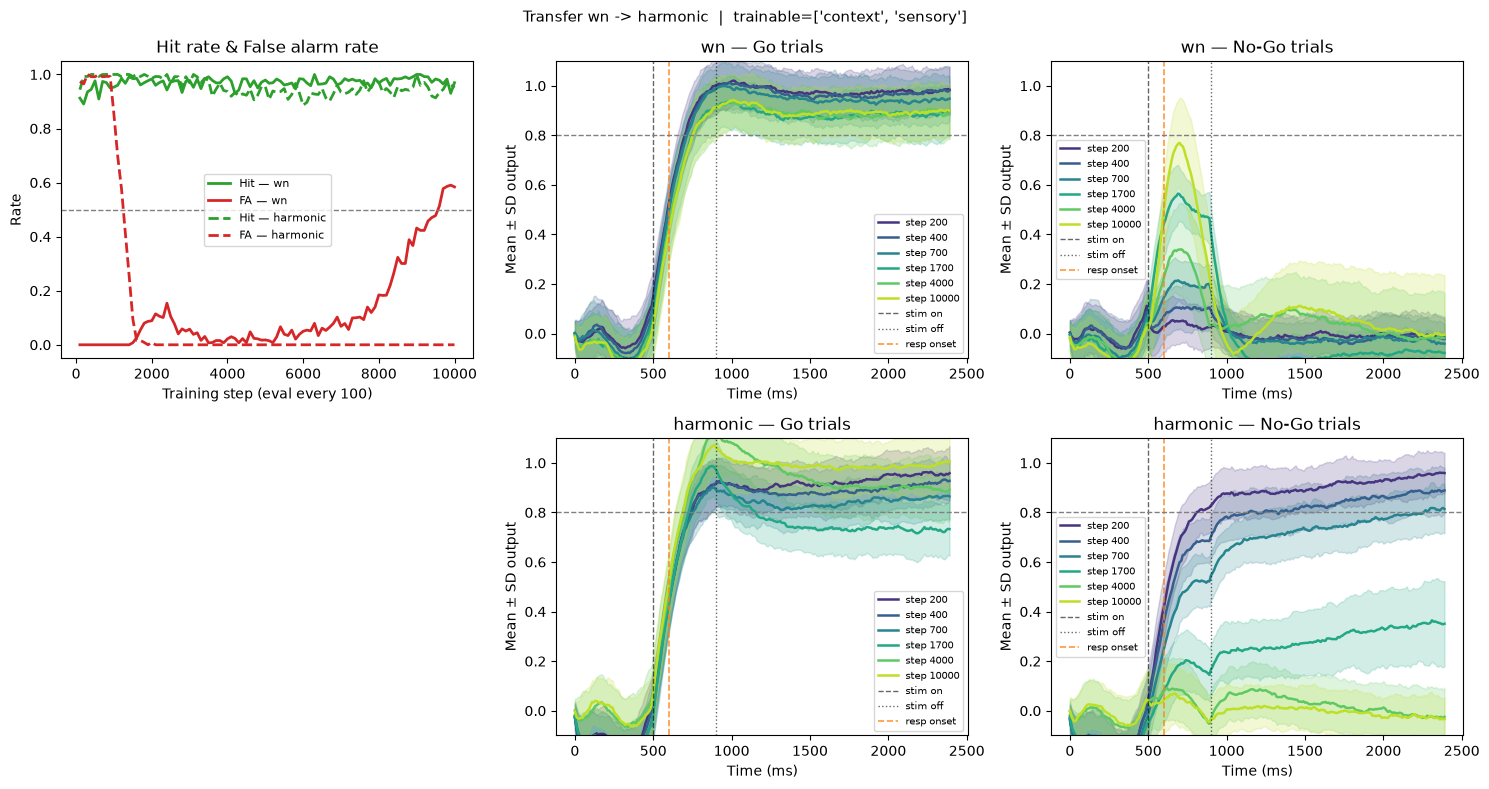

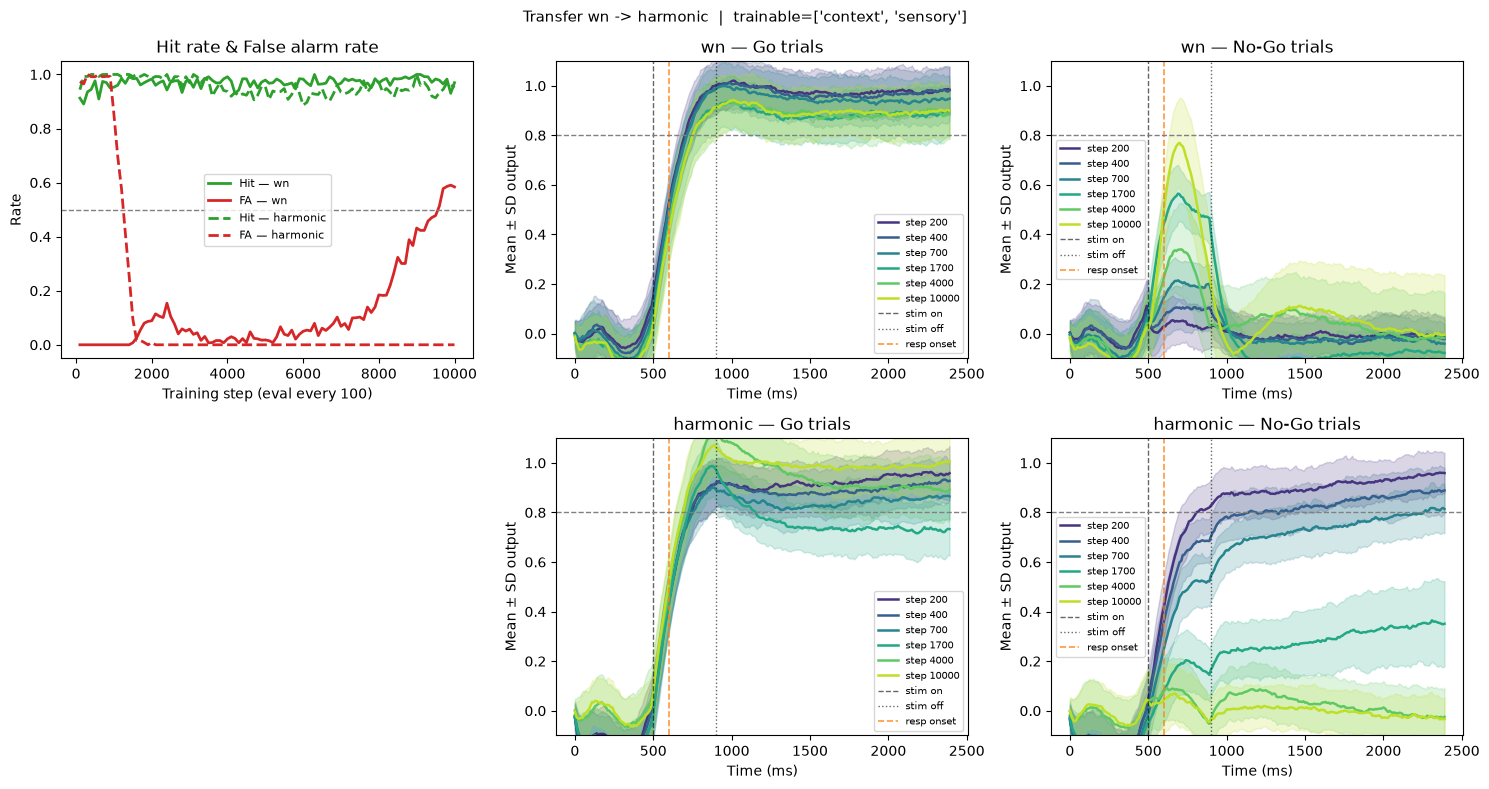

In [7]:
plot_training_log(log, cfg,
                  title=f'Transfer {source_task} -> {train_task}  |  trainable={trainable}')


Post-transfer evaluation  [wn -> harmonic | trainable=['context', 'sensory']]
Task          Role         Hit      FA   d-prime
------------------------------------------------
wn            source     0.971   0.613      1.60
harmonic      target     0.908   0.000      5.05


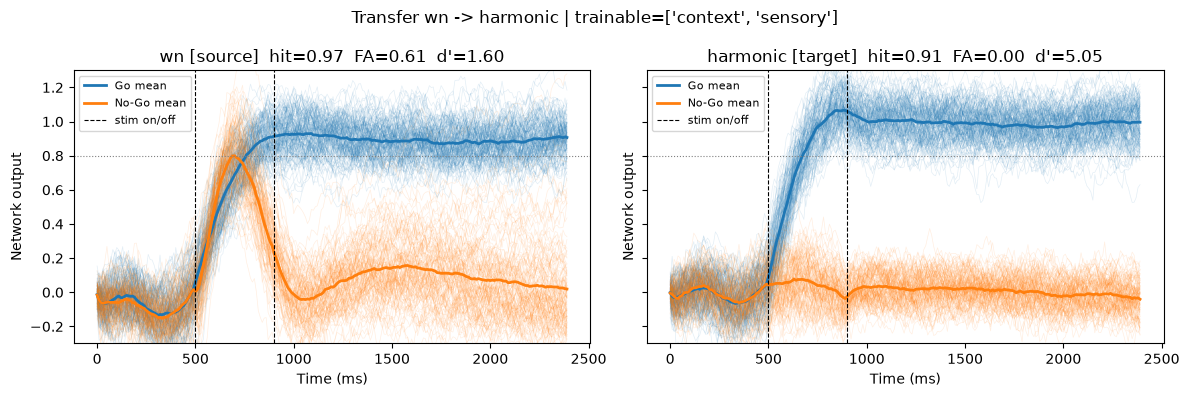

In [8]:

# ── Post-transfer evaluation: print table + final response traces ──────────────
from task import generate_trials
from scipy.stats import norm as _norm

_eval_batch    = 256
_rng_ev        = np.random.default_rng(0)
_key_ev        = jax.random.PRNGKey(0)
stim_on_ev     = cfg['stim_on']
stim_off_ev    = cfg['stim_off']
tdim_ev        = cfg['tdim']
dt_ev          = cfg['dt']
reaction_steps = min(int(2000 / dt_ev), tdim_ev - stim_on_ev)
resp_thresh    = cfg['task_params'].get('response', {}).get('response_thresh', 0.5)

def _eval_task(task, key):
    trial = generate_trials(task, task_list, mode='random',
                            batch_size=_eval_batch, rng=_rng_ev)
    key, nk = jax.random.split(key)
    ys, _ = state.apply_fn({'params': state.params}, jnp.array(trial.x),
                           noise_input=eval_with_noise, noise_rec=True,
                           rngs={'noise': nk})
    ys    = np.array(ys)
    is_go = trial.is_go
    pre   = ys[:stim_on_ev, :, 0].max(axis=0) if stim_on_ev > 0 else np.zeros(_eval_batch)
    post  = ys[stim_on_ev : stim_on_ev + reaction_steps, :, 0].max(axis=0)
    resp  = (post > resp_thresh) & (pre < 0.3)
    hit   = float(resp[is_go].mean())   if is_go.any()    else np.nan
    fa    = float(resp[~is_go].mean())  if (~is_go).any() else np.nan
    eps   = 1e-4
    dp    = _norm.ppf(min(1-eps, max(eps, hit))) - _norm.ppf(min(1-eps, max(eps, fa)))
    return hit, fa, dp, ys, is_go, key

print(f'Post-transfer evaluation  [{source_task} -> {train_task} | trainable={trainable}]')
print(f'{"Task":<12}  {"Role":<8}  {"Hit":>6}  {"FA":>6}  {"d-prime":>8}')
print('-' * 48)
ev_results = {}
for task, role in [(source_task, 'source'), (train_task, 'target')]:
    hit, fa, dp, ys, is_go, _key_ev = _eval_task(task, _key_ev)
    ev_results[task] = (hit, fa, dp, ys, is_go)
    print(f'{task:<12}  {role:<8}  {hit:>6.3f}  {fa:>6.3f}  {dp:>8.2f}')

# ── Response traces: source vs target ─────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
t_ms = np.arange(tdim_ev) * dt_ev
for ax, (task, role) in zip(axes, [(source_task, 'source'), (train_task, 'target')]):
    hit, fa, dp, ys, is_go = ev_results[task]
    for i in np.where(is_go)[0]:
        ax.plot(t_ms, ys[:, i, 0], color='tab:blue', alpha=0.12, lw=0.5)
    for i in np.where(~is_go)[0]:
        ax.plot(t_ms, ys[:, i, 0], color='tab:orange', alpha=0.12, lw=0.5)
    ax.plot(t_ms, ys[:, is_go,  0].mean(axis=1), color='tab:blue',   lw=2, label='Go mean')
    ax.plot(t_ms, ys[:, ~is_go, 0].mean(axis=1), color='tab:orange', lw=2, label='No-Go mean')
    ax.axvline(stim_on_ev  * dt_ev, color='k', lw=0.8, ls='--', label='stim on/off')
    ax.axvline(stim_off_ev * dt_ev, color='k', lw=0.8, ls='--')
    ax.axhline(resp_thresh, color='gray', lw=0.8, ls=':')
    ax.set_title(f"{task} [{role}]  hit={hit:.2f}  FA={fa:.2f}  d'={dp:.2f}")
    ax.set_xlabel('Time (ms)')
    ax.set_ylabel('Network output')
    ax.legend(fontsize=8, loc='upper left')
    ax.set_ylim(-0.3, 1.3)
plt.suptitle(f'Transfer {source_task} -> {train_task} | trainable={trainable}', fontsize=12)
plt.tight_layout()
plt.show()